In [1]:
# [Colab에서 실행할 때만] 주석을 풀고, 아래 DATA_DIR를 '/content/data'로 바꿔서 사용
# from google.colab import files
# uploaded = files.upload()
# !unzip -o -q open*.zip -d /content/data


In [2]:
# @title
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

MIN_N = 5  # 소수 아형 경고 기준 (이 인원 미만이면 표시)
DATA_DIR = '../data'  # 팀 규칙: notebooks/에서 상대 경로 (Colab이면 '/content/data')

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
submission = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

GENE_COLS = [c for c in train.columns if c not in ('ID', 'SUBCLASS')]
train.head()

,ID,SUBCLASS,A2M,AAAS,AADAT,AARS1,ABAT,ABCA1,ABCA2,ABCA3,...,ZNF292,ZNF365,ZNF639,ZNF707,ZNFX1,ZNRF4,ZPBP,ZW10,ZWINT,ZYX
0,TRAIN_0000,KIPAN,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
1,TRAIN_0001,SARC,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
2,TRAIN_0002,SKCM,R895R,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
3,TRAIN_0003,KIRC,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
4,TRAIN_0004,GBMLGG,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT


# 1) train과 test의 행 수, 열 수

In [3]:
print(f"train : {train.shape[0]:,}행 x {train.shape[1]:,}열  (ID + SUBCLASS + 유전자 {len(GENE_COLS):,}개)")
print(f"test  : {test.shape[0]:,}행 x {test.shape[1]:,}열  (ID + 유전자 {test.shape[1]-1:,}개)")
print(f"sample_submission : {submission.shape[0]:,}행 x {submission.shape[1]}열")
print('train/test 유전자 컬럼 동일 여부(집합):', set(GENE_COLS) == set(test.columns[1:]))
print('train/test 유전자 컬럼 순서 동일 여부:', list(train[GENE_COLS].columns) == list(test.columns[1:]))

train : 6,201행 x 4,386열  (ID + SUBCLASS + 유전자 4,384개)
test  : 2,546행 x 4,385열  (ID + 유전자 4,384개)
sample_submission : 2,546행 x 2열
train/test 유전자 컬럼 동일 여부(집합): True
train/test 유전자 컬럼 순서 동일 여부: True


# 2) 결측치 여부

In [4]:
def missing_summary(df, name):
    total = df.isna().sum().sum()
    print(f"[{name}] 전체 결측치: {total}개, 결측 있는 열: {(df.isna().sum() > 0).sum()}개, "
          f"결측 있는 행: {(df.isna().sum(axis=1) > 0).sum()}개")

missing_summary(train, 'train')
missing_summary(test, 'test')

test_na = test.isna().sum()
test_na[test_na > 0].sort_values(ascending=False).to_frame('결측 개수')

[train] 전체 결측치: 0개, 결측 있는 열: 0개, 결측 있는 행: 0개


[test] 전체 결측치: 237개, 결측 있는 열: 25개, 결측 있는 행: 128개


,결측 개수
CNOT2,77
TNFAIP6,65
AK2,29
MYL1,21
RBM5,19
TMEM97,4
PTGES3,3
CCRL2,2
ATP6V1H,1
IER3,1


In [5]:
raw_test = pd.read_csv(f'{DATA_DIR}/test.csv', keep_default_na=False, dtype=str)
print('test 결측 위치의 원본 값:', pd.Series(raw_test.values[test.isna().values]).value_counts().to_dict())

test 결측 위치의 원본 값: {'': 237}


# 3) 변이 값이 어떤 형태로 들어있는지(WT 외에 어떤 표기들이 있고, 각각 몇개씩인지)

In [6]:
cell_values = pd.Series(train[GENE_COLS].values.ravel())
n_cells = len(cell_values)
n_wt = (cell_values == 'WT').sum()
mutated = cell_values[cell_values != 'WT']

print(f"전체 칸: {n_cells:,}")
print(f"WT(변이 없음): {n_wt:,} ({n_wt/n_cells:.2%})")
print(f"변이 있는 칸: {len(mutated):,} ({len(mutated)/n_cells:.2%})")
print(f"  - 한 칸에 변이 여러 개(공백 구분): {mutated.str.contains(' ').sum():,}칸")
print(f"고유 값 개수(WT 제외): {mutated.nunique():,}")

전체 칸: 27,185,184
WT(변이 없음): 26,966,291 (99.19%)
변이 있는 칸: 218,893 (0.81%)
  - 한 칸에 변이 여러 개(공백 구분): 22,026칸
고유 값 개수(WT 제외): 118,846


3)-1 변이 유형별 개수

In [7]:
def mutation_type(token):
    """변이 토큰 1개를 유형으로 분류 (피처 생성에도 재사용 가능)"""
    if 'fs' in token:
        return 'Frameshift (fs)'
    if 'del' in token or 'ins' in token:
        return 'In-frame indel'
    if '>' in token:  # 연속 아미노산 치환 (예: 1529_1530AL>AL)
        before, after = token.split('>')
        ref = before.lstrip('0123456789_')
        if ref == after:
            return 'Silent (동의)'
        if '*' in after and '*' not in ref:
            return 'Nonsense (*)'
        return 'Missense'
    m = re.fullmatch(r'([A-Z*])(\d+)([A-Z*])', token)
    if m:
        ref, alt = m.group(1), m.group(3)
        if ref == alt:  # *261* (정지코돈 유지)도 여기
            return 'Silent (동의)'
        if alt in ('*', 'X'):  # 'X'도 종결코돈 (test 표기, 3)-4 참고)
            return 'Nonsense (*)'
        if ref == '*':
            return 'Stop-loss'
        return 'Missense'
    return 'Other'

tokens = Counter(t for v in mutated for t in v.split())
type_counts = Counter()
examples = {}
for tok, n in tokens.items():
    t = mutation_type(tok)
    type_counts[t] += n
    examples.setdefault(t, [])
    if len(examples[t]) < 3:
        examples[t].append(tok)

total_tok = sum(type_counts.values())
type_table = pd.DataFrame({
    '개수': pd.Series(type_counts),
    '비율(%)': (pd.Series(type_counts) / total_tok * 100).round(2),
    '예시': pd.Series({k: ', '.join(v) for k, v in examples.items()}),
}).sort_values('개수', ascending=False)
print(f'변이 토큰 총 {total_tok:,}개')
type_table

변이 토큰 총 255,164개


,개수,비율(%),예시
Missense,164849,64.61,"F736C, P117R, R305S"
Silent (동의),67049,26.28,"D623D, G592G, K277K"
Nonsense (*),13352,5.23,"E237*, W95*, Q110*"
Frameshift (fs),9911,3.88,"L1854fs, G692fs, C375fs"
In-frame indel,3,0.00,"249del, 490del, R649del"


In [8]:
# 분류 규칙 점검: '*'로 시작하는 토큰, '>' 치환 토큰이 어떻게 분류되는지 확인
star = {t: n for t, n in tokens.items() if t.startswith('*')}
print(f"'*'로 시작하는 토큰: 고유 {len(star)}개 / 총 {sum(star.values())}개")
print('  분류 결과:', dict(Counter(mutation_type(t) for t in star for _ in range(star[t]))))
print('  예시:', list(star)[:5])

multi = {t: n for t, n in tokens.items() if '>' in t}
print(f"'>' 치환 토큰: 고유 {len(multi)}개 / 총 {sum(multi.values())}개")
print('  분류 결과:', dict(Counter(mutation_type(t) for t in multi for _ in range(multi[t]))))
print('  Other로 남은 토큰:', [t for t in tokens if mutation_type(t) == 'Other'])

'*'로 시작하는 토큰: 고유 82개 / 총 101개
  분류 결과: {'Silent (동의)': 99, 'Frameshift (fs)': 2}
  예시: ['*261*', '*931*', '*1217*', '*990*', '*214fs']
'>' 치환 토큰: 고유 222개 / 총 239개
  분류 결과: {'Silent (동의)': 67, 'Nonsense (*)': 63, 'Missense': 109}
  Other로 남은 토큰: []


3)-2 최다 변이

In [9]:
pd.Series(tokens).sort_values(ascending=False).head(10).to_frame('개수')

,개수
R132H,349
V600E,332
E545K,158
H1047R,154
R273C,100
R175H,76
E542K,76
R273H,72
R132C,60
R248Q,59


3)-3 train vs test 변이 표기 비교

위 3)-1, 3)-2는 train만 본 결과입니다. test도 같은 방식으로 표기되어 있는지 패턴별로 세어 비교합니다.
- 이 노트북은 test를 기본 옵션으로 읽어서 빈칸 237개가 NaN입니다 → `dropna()`로 제외

In [10]:
def get_tokens(df):
    """변이 있는 칸(WT·빈칸 제외)과 그 안의 토큰을 모두 꺼냅니다."""
    v = df[GENE_COLS].stack().dropna()  # test 빈칸(NaN) 제외
    v = v[v != 'WT']
    return v, pd.Series([t for cell in v for t in cell.split()])

PATTERNS = {
    'R213* (종결, * 표기)':          r'[A-Z]\d+\*',
    'R492X (종결, X 표기)':          r'[A-Z]\d+X',
    'M622fs (frameshift)':           r'[A-Z*]?\d+fs',
    'K600?fs (fs 앞에 아미노산 1글자)': r'[A-Z*]?\d+[A-Z]fs.*',
    'del / ins (in-frame indel)':    r'.*(del|ins).*',
}
cells_by, toks_by, rows = {}, {}, {}
for name, df in [('train', train), ('test', test)]:
    cells, toks = get_tokens(df)
    cells_by[name], toks_by[name] = cells, toks
    r = {k: int(toks.str.fullmatch(p).sum()) for k, p in PATTERNS.items()}
    r['토큰 총수'] = len(toks)
    r['환자당 토큰 수'] = round(len(toks) / len(df), 1)
    r['여러 토큰 칸 비율(%)'] = round(cells.str.contains(' ').mean() * 100, 1)
    n_gene = df[GENE_COLS].notna().where(df[GENE_COLS] != 'WT', False).sum(axis=1)
    r['환자당 변이 유전자 수(중앙값)'] = float(n_gene.median())
    rows[name] = r
pd.DataFrame(rows)

,train,test
"R213* (종결, * 표기)",13289.0,1961.0
"R492X (종결, X 표기)",0.0,14477.0
M622fs (frameshift),8618.0,3338.0
K600?fs (fs 앞에 아미노산 1글자),0.0,22221.0
del / ins (in-frame indel),3.0,4270.0
토큰 총수,255164.0,337512.0
환자당 토큰 수,41.1,132.6
여러 토큰 칸 비율(%),10.1,31.8
환자당 변이 유전자 수(중앙값),14.0,28.0


3)-4 `*`와 `X`는 같은 종결코돈인가?

HGVS 표기법에서 종결코돈은 `*`(현재 표기) 또는 `X`(예전 표기)로 씁니다. 결실은 `del`로 따로 씁니다.
데이터로도 확인합니다. 종결코돈(TAA·TAG·TGA)은 **염기 1개 치환으로 생길 수 있는 아미노산이 Q, E, K, R, W, S, Y, L, C, G로 정해져 있습니다.**
기호 앞 아미노산이 거의 이 10개뿐이면 종결코돈, 다른 아미노산도 섞여 있으면 종결코돈이 아닙니다.

In [11]:
STOP_REACHABLE = set('QEKRWSYLCG')  # 염기 1개 치환으로 종결코돈이 될 수 있는 아미노산

def ref_aa_check(toks, pattern):
    ref = toks[toks.str.fullmatch(pattern)].str[0]
    return {'개수': len(ref),
            '종결 가능 아미노산 비율(%)': round(ref.isin(STOP_REACHABLE).mean() * 100, 1),
            '상위 아미노산': ', '.join(f'{a}({n})' for a, n in ref.value_counts().head(5).items())}

pd.DataFrame({
    'train  R213*':            ref_aa_check(toks_by['train'], r'[A-Z]\d+\*'),
    'test   R213*':            ref_aa_check(toks_by['test'],  r'[A-Z]\d+\*'),
    'test   R492X':            ref_aa_check(toks_by['test'],  r'[A-Z]\d+X'),
    'test   E156del (비교용)':  ref_aa_check(toks_by['test'],  r'[A-Z]\d+del'),
    'train  missense (기준선)': ref_aa_check(toks_by['train'], r'[A-Z]\d+[A-Z]'),
}).T

,개수,종결 가능 아미노산 비율(%),상위 아미노산
train R213*,13289,99.9,"E(3452), R(3392), Q(2527), W(1071), S(1048)"
test R213*,1961,99.9,"R(470), Q(448), E(358), W(202), S(148)"
test R492X,14477,99.1,"R(4987), E(4399), Q(1759), S(888), Y(651)"
test E156del (비교용),1680,77.7,"E(366), K(345), Q(209), S(146), L(106)"
train missense (기준선),231623,55.0,"R(30283), S(20057), E(18691), L(18619), P(18216)"


3)-5 test의 '한 칸 여러 토큰'은 이소폼 중복인가?

test는 `R141H R114H R234H R273H`처럼 ref/alt가 같고 위치 번호만 다른 토큰이 한 칸에 여러 개 있습니다.
서로 다른 변이라면 번호 간격이 환자마다 제각각이어야 하고, 같은 변이를 이소폼별 번호로 적은 것이라면 간격이 항상 같아야 합니다.

In [12]:
POS = re.compile(r'^([A-Z*])(\d+)(.*)$')

def same_change_ratio(cells):
    """여러 토큰 칸 중 모든 토큰의 ref/alt가 같은(위치만 다른) 칸 비율"""
    multi = cells[cells.str.contains(' ')]
    def same(cell):
        ms = [POS.match(t) for t in cell.split()]
        return all(ms) and len({(m.group(1), m.group(3)) for m in ms}) == 1
    return round(multi.map(same).mean() * 100, 1)

print('여러 토큰 칸 중 ref/alt가 모두 같은 칸 비율(%)')
print('  train:', same_change_ratio(cells_by['train']), ' / test:', same_change_ratio(cells_by['test']))

def offset_patterns(df, gene, top=3):
    """한 칸 안 토큰들의 위치 차이(가장 큰 번호 기준) 패턴 빈도"""
    s = df[gene].dropna()
    s = s[(s != 'WT') & s.str.contains(' ')]
    pats = Counter()
    for cell in s:
        pos = [int(POS.match(t).group(2)) for t in cell.split() if POS.match(t)]
        pats[tuple(sorted(max(pos) - p for p in pos))] += 1
    return len(s), pats.most_common(top)

n, pats = offset_patterns(test, 'TP53')
print(f'\ntest TP53 여러 토큰 칸 {n}개의 위치 차이 패턴 (상위 3개)')
for p, k in pats:
    print(f'  {p}: {k}칸')
print('\n예시:', test['TP53'].dropna().loc[lambda s: s.str.contains('R273H')].head(3).tolist())

여러 토큰 칸 중 ref/alt가 모두 같은 칸 비율(%)
  train: 11.7  / test: 94.0

test TP53 여러 토큰 칸 701개의 위치 차이 패턴 (상위 3개)
  (0, 39, 132, 159): 534칸
  (0, 39, 132): 68칸
  (0, 39): 59칸

예시: ['R141H R114H R234H R273H', 'R141H R114H R234H R273H', 'R273H']


3)-6 test에서 유독 많이 나오는 유전자 (관찰용)

유전자별로 변이가 있는 환자 비율을 train과 test에서 비교합니다.
⚠️ 관찰용입니다. 이 결과(test 빈도)로 유전자를 빼거나 고르면 test 정보를 쓰는 것이므로, 전처리에 쓰려면 대회 규칙 확인과 팀 합의가 필요합니다.

In [13]:
def gene_rate(df):
    return (df[GENE_COLS].notna() & (df[GENE_COLS] != 'WT')).mean()

rate = pd.DataFrame({'train(%)': gene_rate(train) * 100, 'test(%)': gene_rate(test) * 100})
rate['배율(test/train)'] = (rate['test(%)'] + 0.1) / (rate['train(%)'] + 0.1)
print('test 변이 비율 상위 10개 유전자')
display(rate.sort_values('test(%)', ascending=False).head(10).round(1))
print(f"test에서 3배 이상 많은 유전자: {(rate['배율(test/train)'] >= 3).sum()}개 / {len(rate)}개")

test 변이 비율 상위 10개 유전자


,train(%),test(%),배율(test/train)
TP53,28.5,41.3,1.4
AHNAK,5.6,30.4,5.3
TCHH,3.4,28.8,8.2
APC,5.9,27.7,4.6
KMT2D,7.3,19.3,2.6
CACNA1A,3.8,18.9,4.9
SYNE1,10.4,17.4,1.7
MAGEE1,1.8,15.4,8.1
CPEB2,0.6,14.6,20.6
RYR2,10.4,14.2,1.4


test에서 3배 이상 많은 유전자: 631개 / 4384개


# 4) 아형 개수와 환자 수·비율

In [14]:
counts = train['SUBCLASS'].value_counts()
ratio = (counts / len(train) * 100).round(2)
print(f'아형 개수: {counts.shape[0]}개')
pd.DataFrame({'환자 수': counts, '비율(%)': ratio})

아형 개수: 26개


,환자 수,비율(%)
SUBCLASS,,
BRCA,786,12.68
KIPAN,515,8.31
GBMLGG,461,7.43
STES,379,6.11
KIRC,334,5.39
THCA,324,5.22
SKCM,276,4.45
PRAD,266,4.29
OV,253,4.08


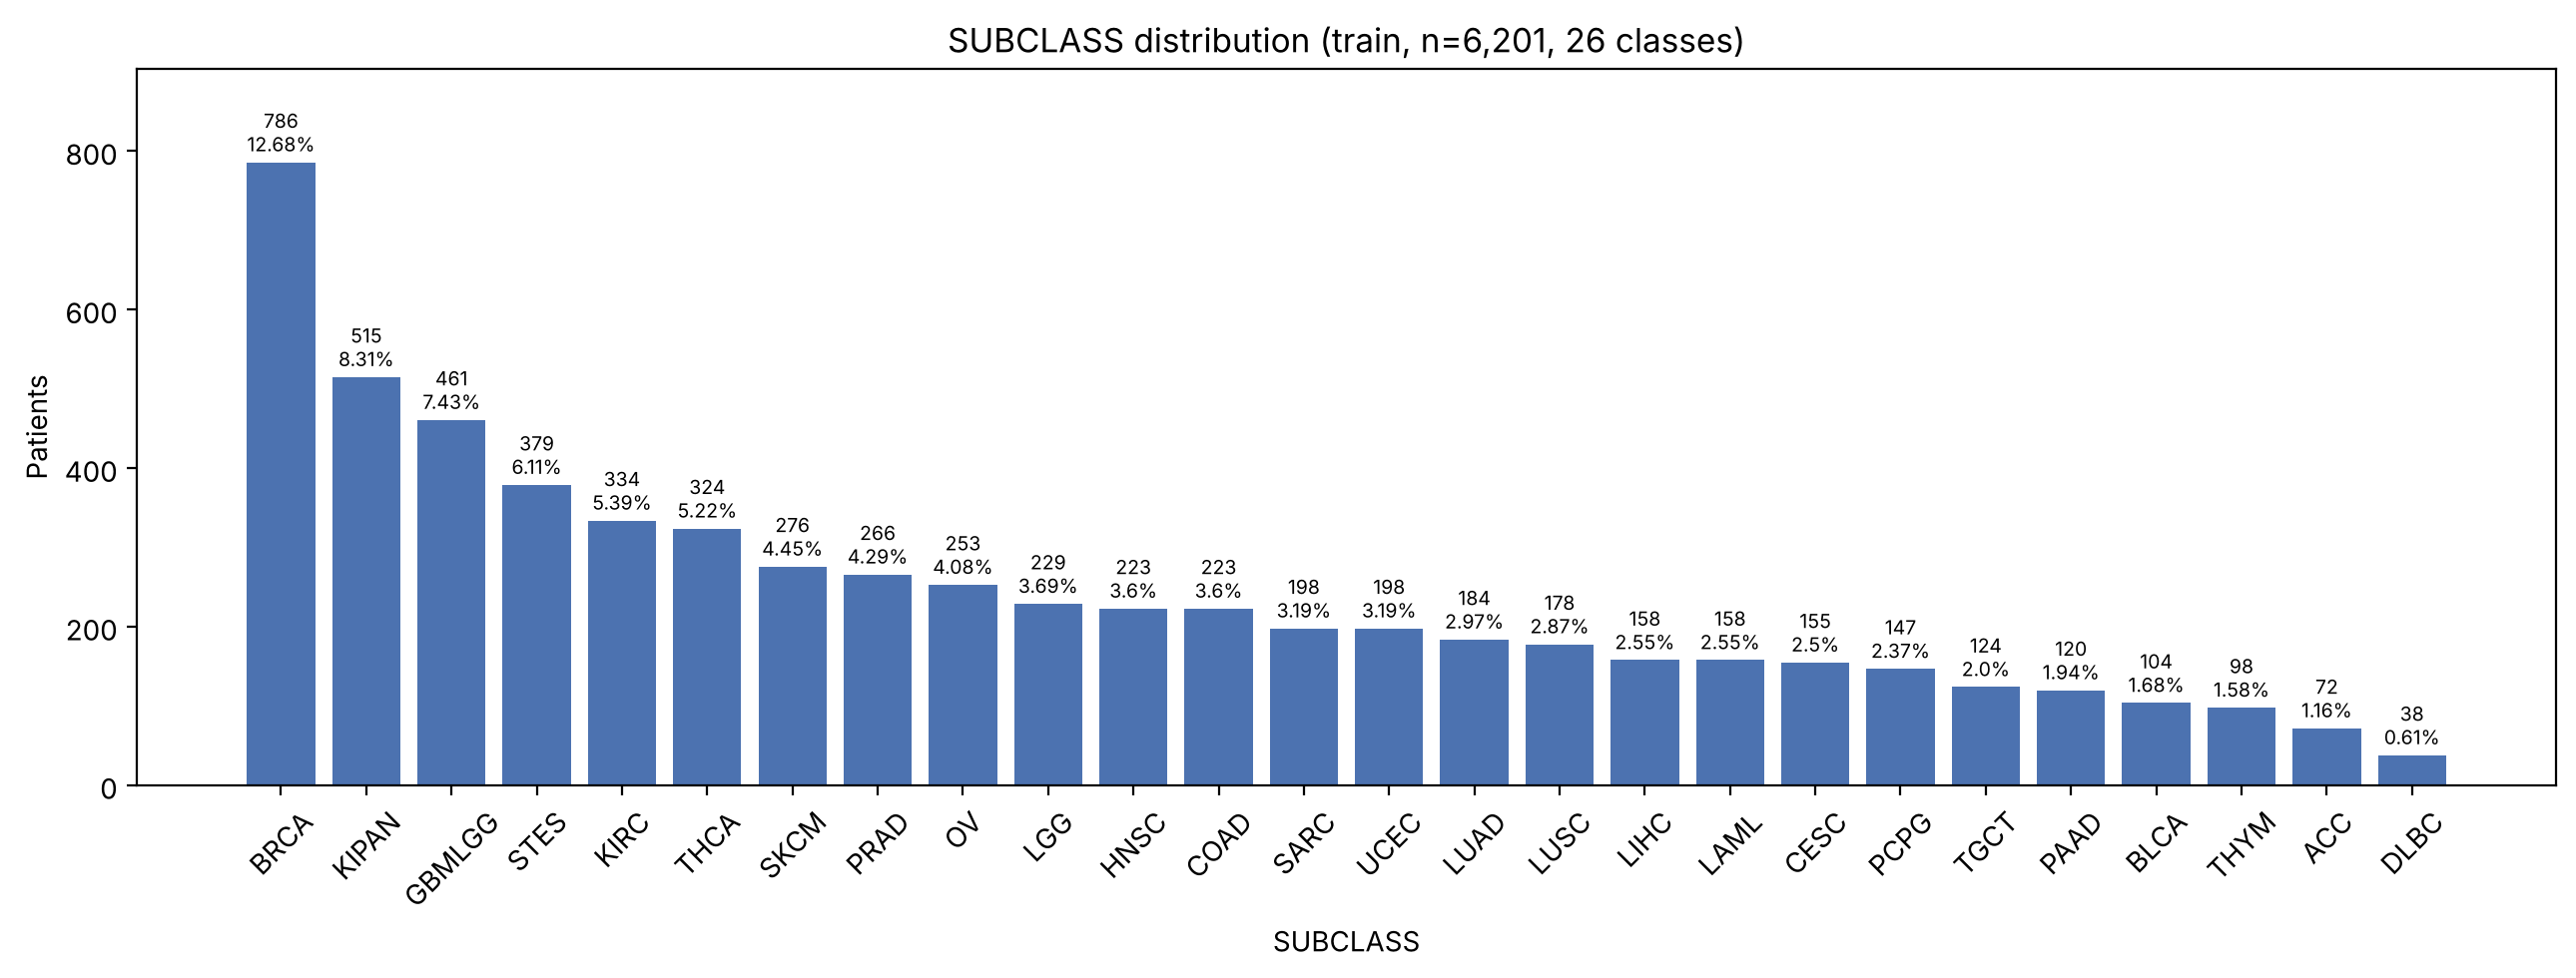

In [15]:
# @title
fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#d62728' if n < MIN_N else '#4c72b0' for n in counts.values]
bars = ax.bar(counts.index, counts.values, color=colors)
for b, n, p in zip(bars, counts.values, ratio.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 8, f'{n}\n{p}%', ha='center', va='bottom', fontsize=7)
ax.set_title(f'SUBCLASS distribution (train, n={len(train):,}, {len(counts)} classes)')
ax.set_xlabel('SUBCLASS')
ax.set_ylabel('Patients')
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5) 가장 적은 아형, 5명 미만 체크

In [16]:
print(f'가장 적은 아형: {counts.idxmin()} ({counts.min()}명, {ratio.min()}%)')
print(f'가장 많은 아형: {counts.idxmax()} ({counts.max()}명, {ratio.max()}%) '
      f'→ 최대/최소 {counts.max()/counts.min():.1f}배')

small = counts[counts < MIN_N]
print(f'{MIN_N}명 미만인 아형: 없음' if small.empty else f'⚠️ {MIN_N}명 미만인 아형: {small.to_dict()}')

가장 적은 아형: DLBC (38명, 0.61%)
가장 많은 아형: BRCA (786명, 12.68%) → 최대/최소 20.7배
5명 미만인 아형: 없음


# 6) 요약

### 1. 데이터 기본 확인
- **크기**: train 6,201행 × 4,386열 (ID, SUBCLASS, 유전자 4,384개), test 2,546행 × 4,385열
- **컬럼**: train·test 유전자 컬럼은 이름과 **순서까지 동일** → `.values`로 바로 모델에 넣어도 됨
- **결측치**: train 0개 / test 237칸 (128명, 유전자 25개)이 실제 빈칸 (`''`)
  - CNOT2(77), TNFAIP6(65), AK2(29)에 집중
  - 빈칸은 `'WT'`로 채우는 고정 규칙만 사용 (test 통계값으로 채우면 Data Leakage)
- **변이 값 형태** (train 기준): 99.19%가 WT, 변이 있는 칸 0.81% → 매우 희소
  - 22,026칸은 변이가 여러 개 (공백 구분) → 피처 생성 시 `split()` 필요
- **변이 유형** (train 토큰 255,164개 기준, 예시는 출력값)
  - Missense 64.61% (F736C) · Silent 26.28% (D623D) · Nonsense 5.23% (E237*) · Frameshift 3.88% (L1854fs) · In-frame indel 0.00% (249del, 3개)
  - `1529_1530AL>AL`처럼 `>`가 있는 연속 치환(239개)은 앞뒤를 비교해 Silent 67 / Nonsense 63 / Missense 109로 분류
  - `*261*`처럼 `*`로 시작하는 토큰 101개: 정지코돈 유지 99개 → Silent, `*214fs` 2개 → Frameshift (Stop-loss `*123W` 형태는 없음)
- **많이 나온 변이**: R132H(349), V600E(332), E545K(158), H1047R(154), R273C(100)

### 2. train vs test 변이 표기 차이 (3)-3 ~ 3)-6)
- **test는 train과 표기 방식이 다릅니다** → 같은 규칙으로 통일해야 함 (`src/data.py`의 `load_data(normalize=True)`)

| 항목 | train | test |
|---|---|---|
| 종결코돈 `R213*` | 13,289 | 1,961 |
| 종결코돈 `R492X` | 0 | 14,477 |
| frameshift `K600?fs` (fs 앞 아미노산 1글자) | 0 | 22,221 |
| del / ins | 3 | 4,270 |
| 환자당 토큰 수 | 41.1 | 132.6 |
| 여러 토큰 칸 비율 | 10.1% | 31.8% |
| 환자당 변이 유전자 수 (중앙값) | 14 | 28 |

- **`X` = `*` = 종결코돈** (3)-4): 기호 앞 아미노산 중 종결코돈이 될 수 있는 아미노산 비율이 `*` 99.9%, `X` 99.1% (결실 `del` 77.7%, missense 기준선 55.0%)
  - 지금의 `mutation_type()` 규칙만 쓰면 `X` 14,477개가 Missense로 잘못 분류됨 → 위 함수에 `X` 처리 추가
- **test의 '한 칸 여러 토큰'은 이소폼 중복** (3)-5): ref/alt가 모두 같은 칸이 test 94.0% (train 11.7%)
  - test TP53 여러 토큰 칸 701개 중 534개가 위치 차이 (0, 39, 132, 159) = TP53 이소폼(Δ40, Δ133, Δ160) 번호 차이
  - 같은 변이를 이소폼별 번호로 여러 번 적은 것 → 가장 큰 번호(기본 이소폼, train 표기) 1개만 남김
- **정규화 후에도 남는 차이**: test 환자당 변이 유전자 수가 train의 약 2배, 일부 유전자는 test에서 유독 많음 (TCHH 3.4%→28.8%, CPEB2 0.6%→14.6%, 3배 이상인 유전자 631개)
  - 변이 '개수' 피처는 분포가 어긋나므로 주의
  - test 빈도를 보고 유전자를 빼는 것은 test 정보를 쓰는 것 → 대회 규칙 확인·팀 합의 필요 (3)-6은 관찰용)

### 3. 타깃 확인 (SUBCLASS)
- 아형 **26개**
- 가장 많은 아형: BRCA 786명 (12.68%) / 가장 적은 아형: **DLBC 38명 (0.61%)** → 약 20.7배 차이
- **5명 미만 아형 없음** → Stratified 5-fold로 나눠도 fold마다 모든 아형 포함 (DLBC fold당 약 7~8명)
- 모델링 참고
  - Macro F1이라 DLBC, ACC, THYM 같은 소수 아형도 똑같이 반영 → class_weight 등 불균형 처리 필요
  - LGG↔GBMLGG, KIRC↔KIPAN은 이름이 겹쳐 헷갈릴 수 있음 → 혼동행렬로 확인 필요